# Video Preprocessing Pipeline

Step-by-step walkthrough of the preprocessing pipeline used to prepare the
leukemia chromatin microscopy videos for optical flow estimation:
**normalize -> detect & localize the cell -> register (stabilize) -> temporal
CLAHE contrast enhancement**.

Runs on the bundled sample clip (`example_video.tif`, 900 real frames,
cropped to 240x240 around the cell) so it works with no external dataset.
Detection defaults to **SAM 2** (`configs/default_params.py`'s own default --
itself seeded by a Hough circle fit, see Step 3) and falls back to Hough
alone if no SAM 2 checkpoint is configured, so the notebook still runs with
no checkpoint. Each step below calls the actual functions from this repo
(`image_utils.py`, `cell_detection.py`, `registration.py`, `clahe.py`) --
this notebook is the same pipeline as `pipeline.py`'s `run_full_pipeline`,
just broken into inspectable steps. Run this notebook from the `examples/`
folder.

In [1]:
import os
import sys

sys.path.insert(0, os.path.abspath(".."))  # repo root: configs/, image_utils.py, ...

import numpy as np
import matplotlib.pyplot as plt
from aicsimageio import AICSImage

from configs import default_params as config

plt.rcParams["figure.facecolor"] = "white"
plt.rcParams["axes.titlesize"] = 11

# DETECTION_METHOD is left at whatever configs/default_params.py has ("sam"
# by default) -- Step 3 below tries it and falls back to Hough on its own if
# no checkpoint is configured. The other two overrides are just for this
# notebook's own output folder and debug grids:
config.DEBUG_DETECTION = False     # compare_detections always needs an ellipse fit too; skip it here
config.OUTPUT_DIR = "output"       # where registration.py writes its own debug images
os.makedirs(config.OUTPUT_DIR, exist_ok=True)

from image_utils import normalize_frame, imadjust, compute_global_max
from cell_detection import detect_cell_hough, detect_cell_sam, load_sam
from registration import initial_pass, refine_iterative
from clahe import apply_clahe_to_frames

/home/migueldi/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## Step 1 -- Load the video

`AICSImage` reads the `.nd2` microscopy format (and, for this example, an
OME-TIFF excerpt with the exact same API -- see `examples/run_example.py`
for how it was made). Frames come back as `(T, Y, X)` `uint16`.

In [2]:
VIDEO_PATH = "example_video.tif"
reader = AICSImage(VIDEO_PATH)
num_frames = reader.dims.T
print(f"Frames: {num_frames}, size: {reader.dims.Y}x{reader.dims.X}, dtype: {reader.dtype}")

global_max = compute_global_max(reader, channel=0)
print(f"Global max intensity (used to normalize every frame to [0, 1]): {global_max:.0f}")

Frames: 900, size: 240x240, dtype: uint16
Global max intensity (used to normalize every frame to [0, 1]): 23873


## Step 2 -- Normalize and contrast-adjust

Every frame is divided by the video's global max intensity (`normalize_frame`,
so brightness is comparable across the whole acquisition) and then stretched
with a percentile-based contrast adjustment (`imadjust`, MATLAB-style) to
make the cell boundary easier to pick out for detection and tracking.

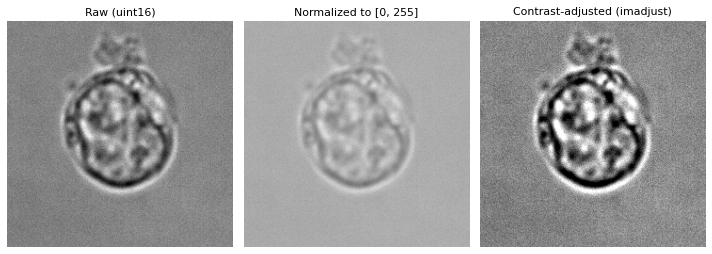

In [3]:
frame0_raw = reader.get_image_data("YX", T=0, C=0)
frame0_u8 = normalize_frame(frame0_raw, global_max)
frame0_adj = imadjust(frame0_u8, tol=1)

fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
axes[0].imshow(frame0_raw, cmap="gray")
axes[0].set_title("Raw (uint16)")
axes[1].imshow(frame0_u8, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Normalized to [0, 255]")
axes[2].imshow(frame0_adj, cmap="gray", vmin=0, vmax=255)
axes[2].set_title("Contrast-adjusted (imadjust)")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

## Step 3 -- Detect and localize the cell

The real default (`configs/default_params.py`, `DETECTION_METHOD = "sam"`)
is **SAM 2**, which gives the most accurate mask -- but SAM 2 itself is
*seeded by a Hough circle fit*: `detect_cell_sam` first calls
`detect_cell_hough` internally and uses that rough circle to build the box
and point prompts it feeds to the model. So Hough runs either way; SAM 2
just refines it into a real segmentation mask when a checkpoint is
available. `detect_cell_ellipse` (classical CV, Canny + morphology) is a
third, checkpoint-free alternative, also seeded the same way.

This cell tries SAM 2 and falls back to plain Hough if no checkpoint is
configured in `configs/default_params.py` (`SAM_CHECKPOINT`), so the
notebook still runs either way.

[SAM 2] Loading model config=configs/sam2.1/sam2.1_hiera_s.yaml | weights=/tmp/sam2.1_hiera_small.pt (cuda)...
[SAM 2] Model loaded.
Detection method used: sam
{'cx': 119, 'cy': 114, 'r': 65, 'crop_side': 182, 'half': 91, 'crop_x1': 58, 'crop_y1': 53, 'crop_x2': 240, 'crop_y2': 235, 'padded_size': (300, 300), 'method': 'sam'}


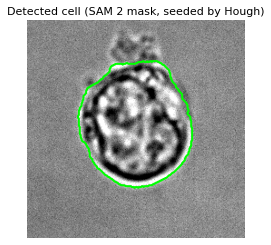

In [4]:
guide_info = None
detection_method_used = None

if config.DETECTION_METHOD == "sam":
    try:
        sam_predictor = load_sam(
            checkpoint=config.SAM_CHECKPOINT,
            model_type=getattr(config, "SAM_MODEL_CONFIG", "vit_s"),
            device=getattr(config, "SAM_DEVICE", "cuda"),
        )
        guide_info = detect_cell_sam(frame0_adj, sam_predictor, border=30, save_debug=False)
        detection_method_used = "sam"
    except Exception as e:
        print(f"[!] SAM 2 not available ({e}); falling back to Hough.")

if guide_info is None:
    guide_info = detect_cell_hough(frame0_adj, border=30, save_debug=False)
    detection_method_used = "hough"

config.DETECTION_METHOD = detection_method_used  # so Step 6 below reuses the same, already-working method
print(f"Detection method used: {detection_method_used}")
print({k: v for k, v in guide_info.items() if not k.startswith("_")})

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(frame0_adj, cmap="gray")
if guide_info.get("_sam_mask") is not None:
    ax.contour(guide_info["_sam_mask"], levels=[127], colors="lime", linewidths=2)
    ax.set_title("Detected cell (SAM 2 mask, seeded by Hough)")
else:
    ax.add_patch(plt.Circle((guide_info["cx"], guide_info["cy"]), guide_info["r"],
                             color="lime", fill=False, linewidth=2))
    ax.set_title("Detected cell (Hough circle)")
ax.axis("off")
plt.show()

## Step 4 -- Register (stabilize) the video

`initial_pass` does one forward Lucas-Kanade pass: it tracks keypoints
around the detected cell frame-to-frame, fits a rigid (rotation +
translation) transform with RANSAC, and warps + crops every frame onto the
first one. `refine_iterative` then alternates backward/forward passes
(`config.N_ITER` times) to refine that alignment further. Together these
correct for the stage drift that happens over a real, minutes-long
acquisition.

In [5]:
ratio = config.ORIGINAL_FPS / config.FPS
num_output_frames = int(num_frames / ratio)
print(f"{num_frames} raw frames -> {num_output_frames} output frames at {config.FPS} FPS "
      f"(downsampled from {config.ORIGINAL_FPS} FPS acquisition)")

registration_info = guide_info.copy()
registration_info["r"] = int(guide_info["r"] * config.KPS_RADIUS_FACTOR)
registration_info["half"] = guide_info["crop_side"] // 2

clean_frames, tracking_frames = initial_pass(
    reader, num_output_frames, ratio,
    detection_info=registration_info, global_max=global_max, border=30,
    median_blur=config.MEDIAN_BLUR, kps_mode=config.KPS_MODE,
    kps_dilate_iter=config.KPS_DILATE_ITER, kps_erode_iter=config.KPS_ERODE_ITER,
)

clean_frames, tracking_frames = refine_iterative(
    clean_frames=clean_frames, tracking_frames=tracking_frames, n_iter=config.N_ITER,
    median_blur=config.MEDIAN_BLUR, kps_mode=config.KPS_MODE,
    kps_dilate_iter=config.KPS_DILATE_ITER, kps_erode_iter=config.KPS_ERODE_ITER,
)
print(f"\nRegistered {len(clean_frames)} frames.")

900 raw frames -> 72 output frames at 20 FPS (downsampled from 250.0 FPS acquisition)
[+] KPs at start of initial pass: 279
-> Running initial pass (72 frames, forward only)...
  -> Registered 50/72

=== Iteration 1/10 -- backward pass ===
    KPs at start of pass: 233
    -> frame 50/71
=== Iteration 1/10 -- forward pass ===
    KPs at start of pass: 213
    -> frame 50/71
=== Iteration 2/10 -- backward pass ===
    KPs at start of pass: 230
    -> frame 50/71
=== Iteration 2/10 -- forward pass ===
    KPs at start of pass: 223
    -> frame 50/71
=== Iteration 3/10 -- backward pass ===
    KPs at start of pass: 242
    -> frame 50/71
=== Iteration 3/10 -- forward pass ===
    KPs at start of pass: 223
    -> frame 50/71
=== Iteration 4/10 -- backward pass ===
    KPs at start of pass: 240
    -> frame 50/71
=== Iteration 4/10 -- forward pass ===
    KPs at start of pass: 229
    -> frame 50/71
=== Iteration 5/10 -- backward pass ===
    KPs at start of pass: 232
    -> frame 50/71
===

### Before vs. after registration

To see what registration corrects for, the top row below re-crops the raw
frames with a single **fixed** crop box (no stabilization) -- any drift
shows up as the cell shifting inside the frame. The bottom row is the
actual registered output: the cell stays put.

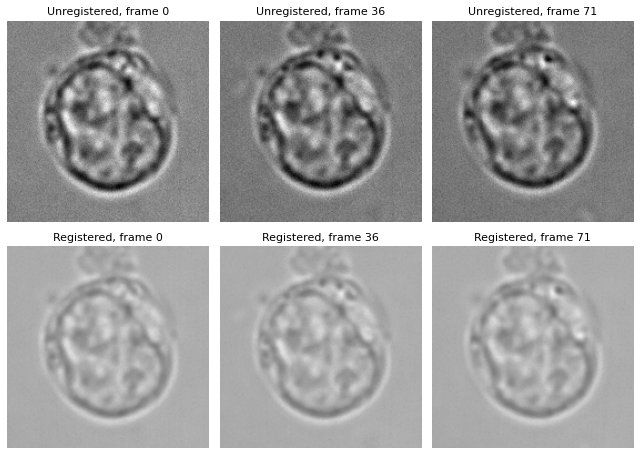

In [6]:
sample_idxs = [0, num_output_frames // 2, num_output_frames - 1]

def unregistered_crop(idx):
    t = int(idx * ratio)
    raw = reader.get_image_data("YX", T=t, C=0)
    u8 = normalize_frame(raw, global_max)
    padded = np.pad(u8, 30, mode="edge")
    c = registration_info
    return padded[c["crop_y1"]:c["crop_y2"], c["crop_x1"]:c["crop_x2"]]

fig, axes = plt.subplots(2, len(sample_idxs), figsize=(9, 6.5))
for col, idx in enumerate(sample_idxs):
    axes[0, col].imshow(unregistered_crop(idx), cmap="gray")
    axes[0, col].set_title(f"Unregistered, frame {idx}")
    axes[1, col].imshow(clean_frames[idx], cmap="gray", vmin=0, vmax=1)
    axes[1, col].set_title(f"Registered, frame {idx}")
for ax in axes.ravel():
    ax.axis("off")
fig.tight_layout()
plt.show()

## Step 5 -- Temporal CLAHE contrast enhancement

`apply_clahe_to_frames` computes one LUT per spatial block (a
`config.CLAHE_BLOCKS` x `config.CLAHE_BLOCKS` grid), pooling histogram
statistics over **every** frame of the registered video -- so the contrast
mapping is fixed for the whole clip and doesn't flicker frame to frame. Each
LUT is applied with bilinear interpolation between neighboring blocks, then
blended back with the original frame outside the cell mask.

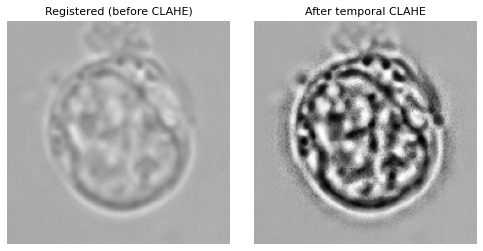

In [7]:
final_info = guide_info.copy()
final_info["cx"] = final_info["cy"] = final_info["half"] = guide_info["crop_side"] // 2

clahe_frames = apply_clahe_to_frames(
    frames=clean_frames, crop_side=final_info["crop_side"], half=final_info["half"],
    hough_r=final_info["r"], ellipse_info=final_info.get("_ellipse"),
    num_blocks=config.CLAHE_BLOCKS, clip_limit=config.CLAHE_CLIP_LIMIT,
)

mid = num_output_frames // 2
fig, axes = plt.subplots(1, 2, figsize=(7, 3.5))
axes[0].imshow(clean_frames[mid], cmap="gray", vmin=0, vmax=1)
axes[0].set_title("Registered (before CLAHE)")
axes[1].imshow(clahe_frames[mid], cmap="gray", vmin=0, vmax=1)
axes[1].set_title("After temporal CLAHE")
for ax in axes:
    ax.axis("off")
fig.tight_layout()
plt.show()

## Putting it all together

`pipeline.py`'s `run_full_pipeline` wraps everything above plus the final
background mask (Gaussian-blurred or flat, see `config.MEDIAN_BACKGROUND`)
and writes the three output videos (`RAW_norm`, `ORIGINAL_norm`,
`CLAHE_<fps>fps.mp4`) -- one call, same steps:

In [8]:
from pipeline import run_full_pipeline

result_info = run_full_pipeline(VIDEO_PATH, config.OUTPUT_DIR)
print(f"\nDone -> {config.OUTPUT_DIR}/")

[+] Saving raw video (unregistered, normalized only)...
[+] Raw video saved to: output/RAW_norm_20fps.mp4
[SAM 2] Loading model config=configs/sam2.1/sam2.1_hiera_s.yaml | weights=/tmp/sam2.1_hiera_small.pt (cuda)...
[SAM 2] Model loaded.
[+] Initial detection (KP guide) completed using: SAM
[+] Preparing ultra-conservative registration...
[DEBUG] KP search area reduced from 65 to 65 pixels.
[+] KPs at start of initial pass: 279
-> Running initial pass (72 frames, forward only)...
  -> Registered 50/72

=== Iteration 1/10 -- backward pass ===
    KPs at start of pass: 233
    -> frame 50/71
=== Iteration 1/10 -- forward pass ===
    KPs at start of pass: 213
    -> frame 50/71
=== Iteration 2/10 -- backward pass ===
    KPs at start of pass: 230
    -> frame 50/71
=== Iteration 2/10 -- forward pass ===
    KPs at start of pass: 223
    -> frame 50/71
=== Iteration 3/10 -- backward pass ===
    KPs at start of pass: 242
    -> frame 50/71
=== Iteration 3/10 -- forward pass ===
    KPs a

In [9]:
from IPython.display import Video

Video(os.path.join(config.OUTPUT_DIR, f"CLAHE_{config.FPS}fps.mp4"), embed=True, width=260)

For a whole folder of `.nd2` files instead of one clip, see `main.py`
(loops over `config.INPUT_DIR`, calling `run_full_pipeline` on each). For how
to install SAM 2 and point `SAM_CHECKPOINT` at a real checkpoint, see the
README's Requirements section.